## **Setup**

In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)

OpenCV version: 4.9.0
NumPy version: 1.26.4


## **What is a Digital Image?**
 (Matrix of Pixels) An image is **not a picture** it is a **3D Matrix (Tensor) of numbers**

Each tiny square is called a **Pixel** (*Picture Element*)

Brightness values range from **0** (Pitch Black) to **255** (Pure Bright White)

In [13]:
# Create a 5x5 matrix with arbitrary numbers between 0 and 255
tiny_matrix = np.array([
    [  0,  50, 100, 150, 200],
    [ 50, 100, 150, 200, 255],
    [100, 150, 200, 255, 150],
    [150, 200, 255, 150, 100],
    [200, 255, 150, 100,   0]
], dtype = np.uint8)

print("Numeric Matrix Array Shape:", tiny_matrix.shape)
print("Numeric Matrix Contents:\n", tiny_matrix)


Numeric Matrix Array Shape: (5, 5)
Numeric Matrix Contents:
 [[  0  50 100 150 200]
 [ 50 100 150 200 255]
 [100 150 200 255 150]
 [150 200 255 150 100]
 [200 255 150 100   0]]


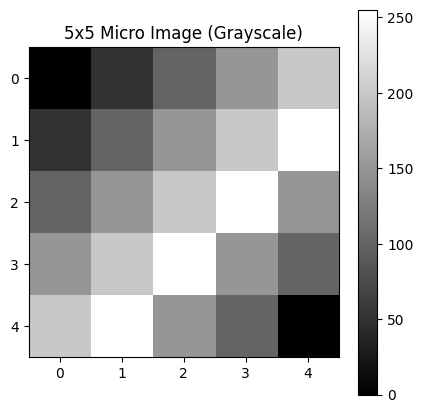

In [14]:
# Plot the matrix visually
plt.figure(figsize = (5, 5))
plt.imshow(tiny_matrix, cmap = 'gray')
plt.title("5x5 Micro Image (Grayscale)")
plt.colorbar()
plt.show()

## **Create a Black & White Image**

In [15]:
black_img = np.zeros((300, 400, 3), dtype = np.uint8)
print("Shape:", black_img.shape)                      # (height , width , color channels)
print("Data type:", black_img.dtype)

Shape: (300, 400, 3)
Data type: uint8


(-0.5, 399.5, 299.5, -0.5)

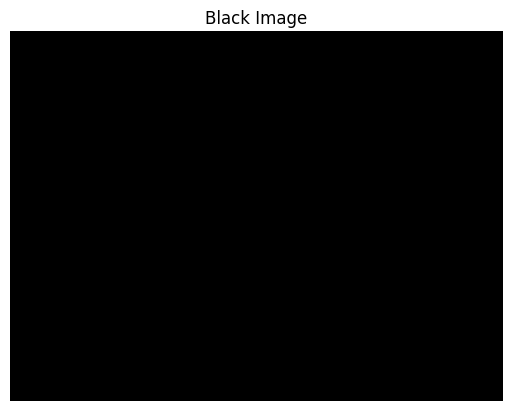

In [16]:
plt.imshow(black_img)
plt.title("Black Image")
plt.axis("off")

(-0.5, 399.5, 299.5, -0.5)

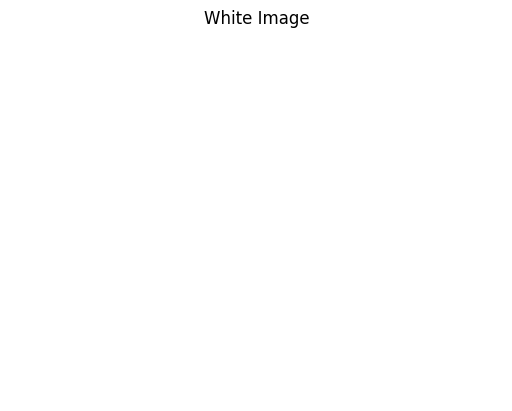

In [17]:
white_img = np.ones((300, 400, 3), dtype=np.uint8) * 255


plt.imshow(white_img)
plt.title("White Image")
plt.axis("off")

## **Create Red Image**

NumPy doesn't inherently know that channel 0 means Blue or Red

In [18]:
red_img = np.zeros((300, 400, 3), dtype = np.uint8)
red_img[:, :, 2] = 255
print(red_img[100, 100])

[  0   0 255]


(-0.5, 399.5, 299.5, -0.5)

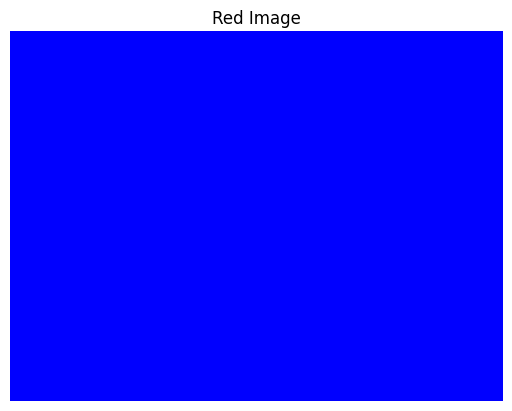

In [19]:
plt.imshow(red_img)
plt.title("Red Image")
plt.axis("off")

(-0.5, 399.5, 299.5, -0.5)

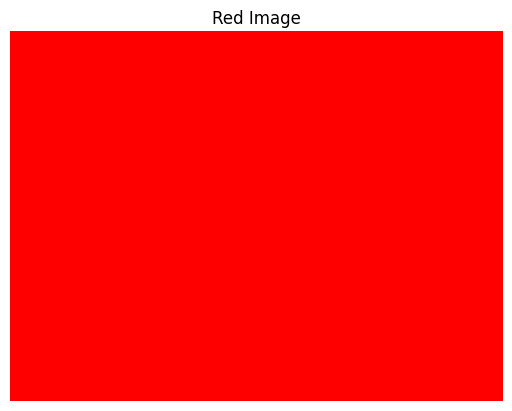

In [20]:
plt.imshow(cv2.cvtColor(red_img, cv2.COLOR_BGR2RGB))
plt.title("Red Image")
plt.axis("off")

## **Create an Image with Shapes**

In [21]:
image = np.zeros((500, 700, 3), dtype = np.uint8)

# Blue rectangle
cv2.rectangle(
    image,
    (50, 50),
    (300, 250),
    (255, 0, 0),
    -1
)

# Green circle
cv2.circle(
    image,
    (500, 170),
    100,
    (0, 255, 0),
    -1
)

# Red line
cv2.line(
    image,
    (50, 400),
    (650, 400),
    (0, 0, 255),
    10
)

# White text
cv2.putText(
    image,
    "OpenCV",
    (230, 350),
    cv2.FONT_HERSHEY_SIMPLEX,
    2,
    (255, 255, 255),
    4
)

array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       ...,

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]]], dtype=uint8)

(-0.5, 699.5, 499.5, -0.5)

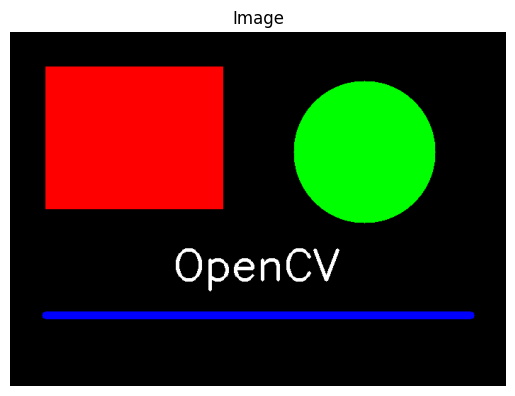

In [50]:
plt.imshow(image)
plt.title("Image")
plt.axis("off")

## **Read an Image with OpenCV**

In [51]:
image_path = "cat.jpg"
img_cv = cv2.imread(image_path)
print("Image loaded:", img_cv is not None)

Image loaded: True


In [52]:
print("Shape:", img_cv.shape)
print("Data type:", img_cv.dtype)

Shape: (597, 335, 3)
Data type: uint8


In [53]:
height, width, channels = img_cv.shape

print("Height:", height)
print("Width:", width)
print("Channels:", channels)

Height: 597
Width: 335
Channels: 3


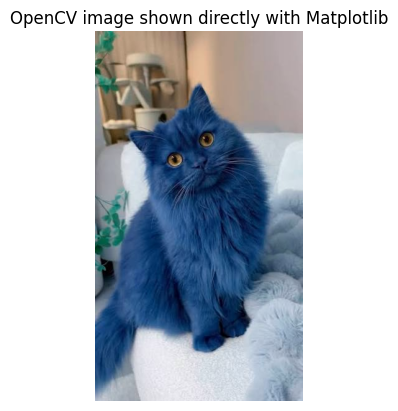

In [54]:
plt.imshow(img_cv)
plt.title("OpenCV image shown directly with Matplotlib")       # OpenCV -->  BGR   but Matplotlib --> RGB
plt.axis("off");

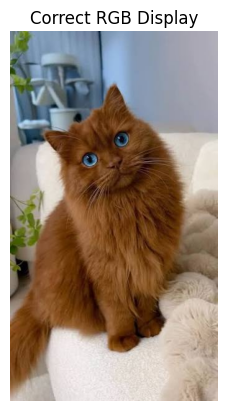

In [55]:
img_rgb = cv2.cvtColor(img_cv, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.title("Correct RGB Display")
plt.axis("off");

## **Grayscale**

In [56]:
gray = cv2.cvtColor(img_cv, cv2.COLOR_BGR2GRAY)
print("Shape:", gray.shape)
print("Dtype:", gray.dtype)

Shape: (597, 335)
Dtype: uint8


In [57]:
print("Color:", img_cv.shape)
print("Gray :", gray.shape)

Color: (597, 335, 3)
Gray : (597, 335)


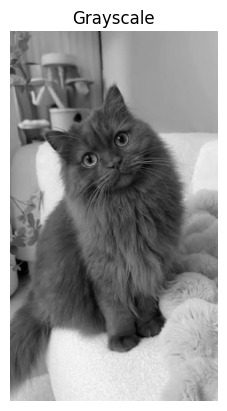

In [58]:
plt.imshow(gray, cmap = "gray")
plt.title("Grayscale")
plt.axis("off");

## **Look at One Pixel**

In [59]:
y = 100
x = 200

color_pixel = img_cv[y, x]
print("Color pixel:", color_pixel)

Color pixel: [181 154 133]


In [60]:
B, G, R = img_cv[y, x]

print("Blue :", B)
print("Green:", G)
print("Red  :", R)

Blue : 181
Green: 154
Red  : 133


In [61]:
gray_pixel = gray[y, x]
print("Grayscale pixel:", gray_pixel)

Grayscale pixel: 151


## **RGBA**

Some images especially PNGs contain an additional channel:

R
G
B
A

where:

A = Alpha / Transparency

In [62]:
rgba = np.zeros((300, 400, 4), dtype = np.uint8)

rgba[:, :, 0] = 255    # Red
rgba[:, :, 3] = 150    # Alpha

In [63]:
print("Shape:", rgba.shape)
print("One pixel:", rgba[100, 100])

Shape: (300, 400, 4)
One pixel: [255   0   0 150]


## **HSV**

RGB/BGR is not the only way to represent color

In [64]:
hsv = cv2.cvtColor(img_cv, cv2.COLOR_BGR2HSV)

print("HSV shape:", hsv.shape)
print("HSV pixel:", hsv[y, x])

HSV shape: (597, 335, 3)
HSV pixel: [107  68 181]


In [65]:
H, S, V = cv2.split(hsv)

print("H shape:", H.shape)
print("S shape:", S.shape)
print("V shape:", V.shape)

H shape: (597, 335)
S shape: (597, 335)
V shape: (597, 335)


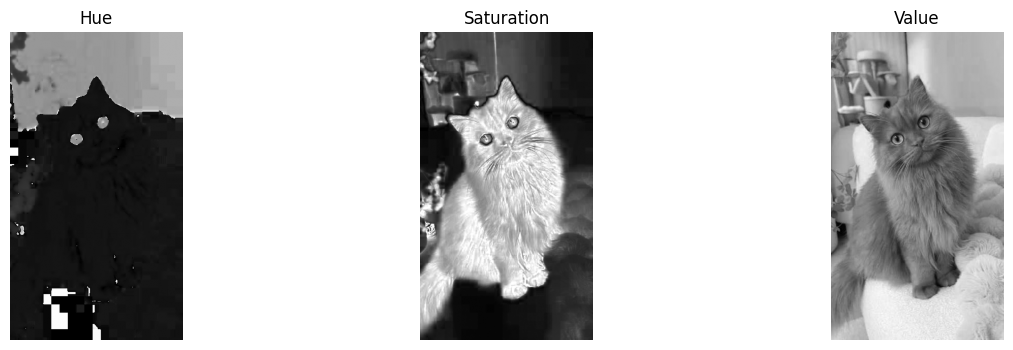

In [37]:
plt.figure(figsize = (15, 4))

plt.subplot(1, 3, 1)
plt.imshow(H, cmap = "gray")
plt.title("Hue")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(S, cmap = "gray")
plt.title("Saturation")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(V, cmap = "gray")
plt.title("Value")
plt.axis("off")

plt.show()

## **LAB**

Another color space

L → Lightness

A → Green <--> Red

B → Blue  <--> Yellow


In [66]:
lab = cv2.cvtColor(img_cv, cv2.COLOR_BGR2LAB)

print("LAB shape:", lab.shape)
print("LAB pixel:", lab[y, x])

LAB shape: (597, 335, 3)
LAB pixel: [160 127 111]


In [67]:
L, A, B = cv2.split(lab)

print("L:", L.shape)
print("A:", A.shape)
print("B:", B.shape)

L: (597, 335)
A: (597, 335)
B: (597, 335)


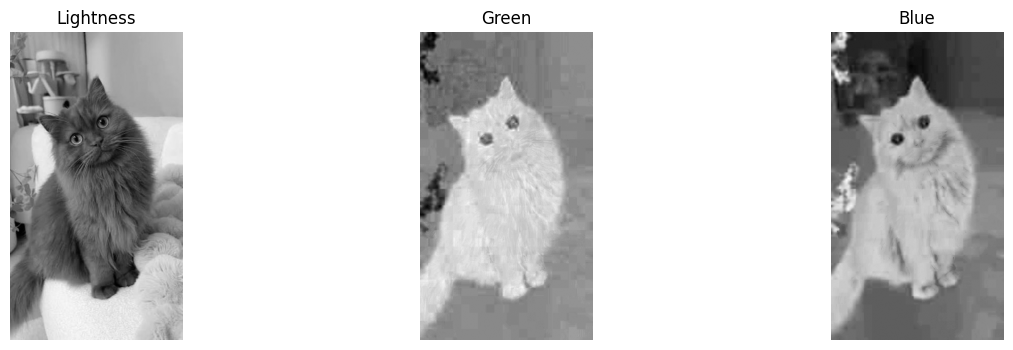

In [68]:
plt.figure(figsize = (15, 4))

plt.subplot(1, 3, 1)
plt.imshow(L, cmap = "gray")
plt.title("Lightness")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(A, cmap = "gray")
plt.title("Green")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(B, cmap = "gray")
plt.title("Blue")
plt.axis("off")

plt.show()

## **Channel Swapping Experiment**

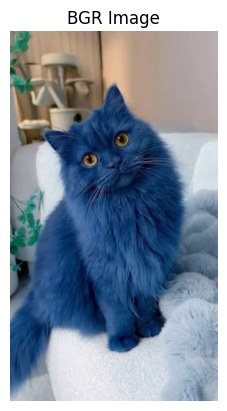

In [69]:
plt.imshow(img_cv)
plt.title("BGR Image")
plt.axis("off");

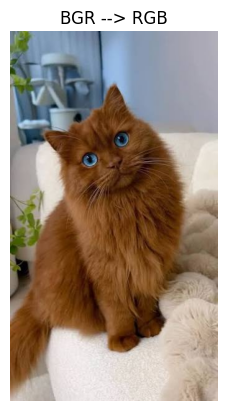

In [42]:
img_rgb = img_cv[:, :, ::-1]

plt.imshow(img_rgb)                 # Matplotlib assumes the array is RGB
plt.title("BGR --> RGB")
plt.axis("off");

## **Split the Color Channels**

In [70]:
B, G, R = cv2.split(img_cv)

print("B shape:", B.shape)
print("G shape:", G.shape)
print("R shape:", R.shape)

B shape: (597, 335)
G shape: (597, 335)
R shape: (597, 335)


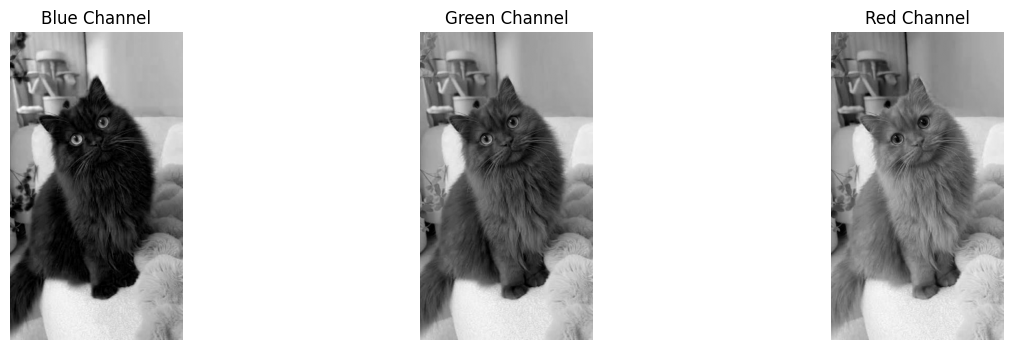

In [71]:
plt.figure(figsize = (15, 4))

plt.subplot(1, 3, 1)
plt.imshow(B, cmap="gray")
plt.title("Blue Channel")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(G, cmap="gray")
plt.title("Green Channel")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(R, cmap="gray")
plt.title("Red Channel")
plt.axis("off")

plt.show()

## **Merge the Channels Again**

In [72]:
merged = cv2.merge([B, G, R])

print("Original shape:", img_cv.shape)
print("Merged shape:", merged.shape)

Original shape: (597, 335, 3)
Merged shape: (597, 335, 3)


In [73]:
print("Are they identical?", np.array_equal(img_cv, merged))

Are they identical? True


Are they identical? False


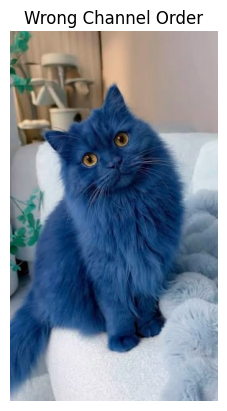

In [74]:
wrong = cv2.merge([R, G, B])
print("Are they identical?", np.array_equal(img_cv, wrong))


plt.imshow(cv2.cvtColor(wrong, cv2.COLOR_BGR2RGB))
plt.title("Wrong Channel Order")
plt.axis("off");

## **Save Images**

In [75]:
cv2.imwrite("outputs/output_color.jpg", img_cv)
cv2.imwrite("outputs/output_gray.jpg", gray)
cv2.imwrite("outputs/output_hsv.jpg", hsv)

True